<a href="https://colab.research.google.com/github/hersil7/cdd_ucsc/blob/main/S3_Entrega2_SILVA_HERNAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 3 — Análisis exploratorio de tu conjunto de datos
**Ciencia de Datos · Semana 3 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 1) · RA3 (transversal) |
| **Duración estimada** | 1,5 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `mi_conjunto_limpio.csv`, producido en la semana 2 |
| **Producto** | Este cuaderno completo — **es la Entrega 2** |
| **Estudiante** | Hernán Silva |

---

⚠️ **Esta semana no hay sesión sincrónica.** El tiempo se destina a este laboratorio, que es el más extenso del curso. Las dudas van al **Foro de Consultas**, con respuesta dentro de 24 horas hábiles.

**Este cuaderno es la entrega.** No hay informe aparte. Lo que se evalúa es que cada resultado venga acompañado de su lectura: *un resultado sin interpretación no es un hallazgo, es un número suelto*.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = '/content/drive/Othercomputers/Notebook HP/Ing Informática UCSC/Trimestre 3/1 Ciencia de datos/Evaluaciones/Semana 2/Lab2/'
SEMILLA = 20263
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

In [ ]:
# Esto se agrega a la Bitácora: Esta lectura permite recuperar el tipo de datos que se pierde al guardar como csv

TIPOS = {
    # Identificadores: texto
    'idrph': ('texto', 'string'), 'conglomerado': ('texto', 'string'), 'estrato': ('texto', 'string'),
    # Ordinales: categoría ordenada
    'mes_central': ('ordinal', 'ordered'), 'mes_encuesta': ('ordinal', 'ordered'),
    'nivel': ('ordinal', 'ordered'), 'cine11_1d': ('ordinal', 'ordered'),
    'nivel_grupo': ('ordinal', 'ordered'),
    # Categóricas sin orden
    'activ': ('categorica', 'category'), 'region': ('categorica', 'category'),
    'tipo': ('categorica', 'category'), 'sexo': ('categorica', 'category'),
    'nacionalidad': ('categorica', 'category'), 'orig1': ('categorica', 'category'),
    'est_conyugal': ('categorica', 'category'), 'estudia_actual': ('categorica', 'category'),
    'parentesco': ('categorica', 'category'), 'termino_nivel': ('categorica', 'category'),
    'categoria_ocupacion': ('categorica', 'category'), 'cae_general': ('categorica', 'category'),
    'ocup_form': ('categorica', 'category'), 'ina_cal_edu': ('categorica', 'category'),
    'plataformas_digitales': ('categorica', 'category'), 'deseo_trabajar': ('categorica', 'category'),
    # Booleanos (1 = sí)
    'proveedor': ('booleano', 'boolean'), 'no_prevision': ('booleano', 'boolean'),
    'ftp': ('booleano', 'boolean'), 'superior_completa': ('booleano', 'boolean'),
    # Numéricos
    'edad': ('entero', 'Int64'), 'habituales': ('entero', 'Int64'),
    'meses_ocup_actual': ('numerica', 'float64'), 'fact_anual': ('numerica', 'float64'),
}

def a_numerico(s):
    return pd.to_numeric(s.astype(str).str.replace(',', '.', regex=False), errors='coerce')

ORDEN_NIVEL_GRUPO = ['Básica o menos', 'Media', 'Superior']

def aplicar_tipos(df, tipos=TIPOS):
    out = df.copy()
    for col, (naturaleza, _) in tipos.items():
        if col not in out.columns:
            continue
        if col == 'nivel_grupo':
            out[col] = pd.Categorical(out[col], categories=ORDEN_NIVEL_GRUPO, ordered=True)
        elif naturaleza == 'texto':
            out[col] = out[col].astype('string')
        elif naturaleza in ('ordinal', 'categorica'):
            num = a_numerico(out[col]).astype('Int64')
            cats = sorted(num.dropna().unique().tolist())
            out[col] = pd.Categorical(num, categories=cats, ordered=(naturaleza == 'ordinal'))
        elif naturaleza == 'booleano':
            s = out[col].astype(str).str.strip().str.upper()
            out[col] = s.map({'TRUE': True, 'FALSE': False, '1': True, '0': False,
                              '1.0': True, '0.0': False}).astype('boolean')
        elif naturaleza == 'entero':
            out[col] = a_numerico(out[col]).round().astype('Int64')
        elif naturaleza == 'numerica':
            out[col] = a_numerico(out[col]).astype('float64')
    return out

In [ ]:
df = aplicar_tipos(pd.read_csv(RUTA + 'mi_conjunto_limpio.csv', sep=';', dtype=str, encoding='utf-8-sig', low_memory=False))
print('Forma:', df.shape)
df.head()

Forma: (118760, 32)


,idrph,mes_central,mes_encuesta,fact_anual,conglomerado,estrato,activ,region,tipo,sexo,...,ocup_form,ina_cal_edu,habituales,meses_ocup_actual,no_prevision,plataformas_digitales,deseo_trabajar,ftp,nivel_grupo,superior_completa
0,966906226666,2,1,93.924863,20043,13100312,3,13,1,2,...,NaN,NaN,<NA>,NaN,<NA>,NaN,2,False,Media,False
1,246247268292,2,1,102.101514,36033,13100313,1,13,1,1,...,1,2,12,500.0,False,2,NaN,<NA>,Superior,True
2,254443118268,2,1,97.354579,36033,13100313,3,13,1,2,...,NaN,NaN,<NA>,NaN,<NA>,NaN,2,False,Superior,True
3,553075369226,2,1,15.743992,14530,3200110,3,3,1,2,...,NaN,NaN,<NA>,NaN,<NA>,NaN,1,False,Básica o menos,False
4,724298626488,2,1,33.690514,13536,8100312,3,8,1,1,...,NaN,NaN,<NA>,NaN,<NA>,NaN,1,True,Superior,True


In [ ]:
df.dtypes

,0
idrph,string[python]
mes_central,category
mes_encuesta,category
fact_anual,float64
conglomerado,string[python]
estrato,string[python]
activ,category
region,category
tipo,category
sexo,category


### Punto de partida

Antes de explorar, recuerda a dónde vas. Copia aquí lo que escribiste en la Entrega 1:

- **Mi pregunta analítica es:**

_¿Qué características personales (sexo, edad, nacionalidad, pertenencia a pueblo originario, estado conyugal y condición de estudiante), educativas (nivel educacional) y territoriales (región y tipo de territorio) se asocian con la desocupación, frente a la ocupación, entre las personas que forman parte de la fuerza de trabajo en 2025?_

- **Una fila de mi conjunto representa:**

Cada fila del dataset de panel (118.760 filas) es **una visita de una persona en un trimestre móvil de 2025**. Más concretamente:

- Una persona aparece exactamente **4 veces**, una por cada trimestre móvil (`mes_central` = 2, 5, 8 y 11).
- Las 4 visitas de una misma persona están separadas **3 meses** entre sí (por ejemplo, meses 1, 4, 7 y 10 de encuesta).
- Por eso el dataset tiene **29.690 personas × 4 visitas = 118.760 filas**.

Las personas no son la unidad de la fila; la fila es la **observación persona-trimestre**. Para análisis a nivel persona hay que agrupar por `idrph`, y para análisis de transiciones hay que ordenar cada persona por `mes_encuesta` y comparar cada visita con la siguiente.

Todo lo que sigue debe servir para responder esa pregunta. Si un gráfico no aporta a ella, sobra.

---
## Parte 1 · Análisis univariado

Una variable a la vez. El objetivo es conocer la forma de cada una antes de relacionarlas.

In [ ]:
# Resumen numérico de todas las variables cuantitativas
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
fact_anual,118760.0,45.701668,41.469061,1.621073,23.872402,35.787832,52.842607,1626.334754
edad,118760.0,42.514744,23.299815,0.0,22.0,43.0,62.0,104.0
habituales,50020.0,38.733467,13.855768,1.0,35.0,44.0,44.0,168.0
meses_ocup_actual,49670.0,94.995651,117.841253,0.0,12.0,48.0,130.0,1016.0


### ✏️ Actividad 1.1 — Distribuciones

Grafica el histograma de **al menos tres variables numéricas** relevantes para tu pregunta. Para cada una, responde en la celda de texto siguiente:

- ¿Es simétrica o asimétrica? ¿Hacia qué lado?
- ¿Tiene una joroba o más de una? Si tiene más de una, **busca la categoría que la explica** (Ejercicio 1 del cuaderno resuelto).
- ¿Ves picos regulares o valores que se repiten sospechosamente? (Ejercicio 3).

**Variable Edad**

Media de edad: 42.514744021556076
Mediana de edad: 43.0
Sesgo: 0.008800573066300003


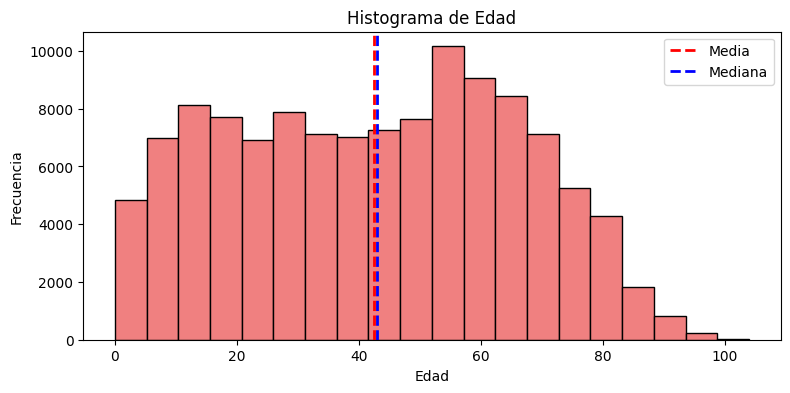

In [ ]:
# histograma de variable edad con media y mediana como líneas verticales
media_edad = df['edad'].mean()
mediana_edad = df['edad'].median()
sesgo_edad = df['edad'].skew()

print('Media de edad:', media_edad)
print('Mediana de edad:', mediana_edad)
print('Sesgo:', sesgo_edad)

plt.hist(df['edad'], bins=20, color='lightcoral', edgecolor='black')
plt.axvline(media_edad, color='red', linestyle='dashed', linewidth=2, label='Media')
plt.axvline(mediana_edad, color='blue', linestyle='dashed', linewidth=2, label='Mediana')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.title('Histograma de Edad')
plt.legend()
plt.show()

In [ ]:
# función que a partir de media, mediana, sesgo determina si la distribución es simétrica, sesgada a la derecha o sesgada a la izquierda
def tipo_distribucion(media, mediana, sesgo):
    if abs(sesgo) < 0.5:
        return 'Simétrica porque el sesgo es cercano a cero'
    elif sesgo > 0:
        return 'Sesgada a la derecha porque el sesgo es mayor a 0.5: {}'.format(sesgo)
    else:
        return 'Sesgada a la izquierda porque el sesgo es menor a -0.5: {}'.format(sesgo)

In [ ]:
print(f'La variable edad tiene una distribución {tipo_distribucion(media_edad, mediana_edad, sesgo_edad)}')

La variable edad tiene una distribución Simétrica porque el sesgo es cercano a cero


* **Jorobas**: No se observan jorobas.
* **Picks irregulares**: No se observan aunque sí se ve una caída paulatina de la frecuencia con la edad, lo cual hace todo el sentido.

**Variable de cantidad de horas habituales de trabajo**

Media de habituales: 38.73346661335466
Mediana de habituales: 44.0
Sesgo: -0.35193325093348216


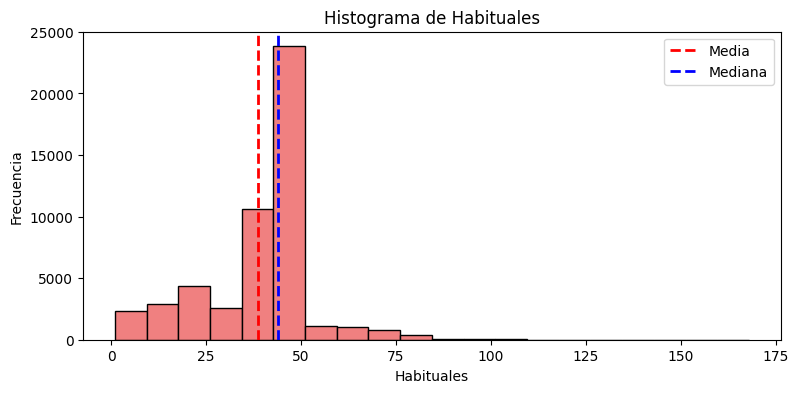

In [ ]:
# histograma de variable habituales con media y mediana como líneas verticales
media_hab = df['habituales'].mean()
mediana_hab = df['habituales'].median()
sesgo_hab = df['habituales'].skew()

print('Media de habituales:', media_hab)
print('Mediana de habituales:', mediana_hab)
print('Sesgo:', sesgo_hab)

plt.hist(df['habituales'], bins=20, color='lightcoral', edgecolor='black')
plt.axvline(media_hab, color='red', linestyle='dashed', linewidth=2, label='Media')
plt.axvline(mediana_hab, color='blue', linestyle='dashed', linewidth=2, label='Mediana')
plt.xlabel('Habituales')
plt.ylabel('Frecuencia')
plt.title('Histograma de Habituales')
plt.legend()
plt.show()

In [ ]:
print(f'La variable habituales tiene una distribución {tipo_distribucion(media_hab, mediana_hab, sesgo_hab)}')

La variable habituales tiene una distribución Simétrica porque el sesgo es cercano a cero


* **Jorobas**: No se observan jorobas.
* **Picks irregulares**: Se observa acumulamiento de casos entre las 30 y 50 horas, cuestión que hace sentido porque se corresponde con la jornada laboral completa que en general está entre las 38 y 45 horas semanales.

**Variable meses_ocup_actual: Duración de la ocupación actual**

Media de meses_ocup_actual: 94.99565129857056
Mediana de meses_ocup_actual: 48.0
Sesgo: 1.8954019418926806


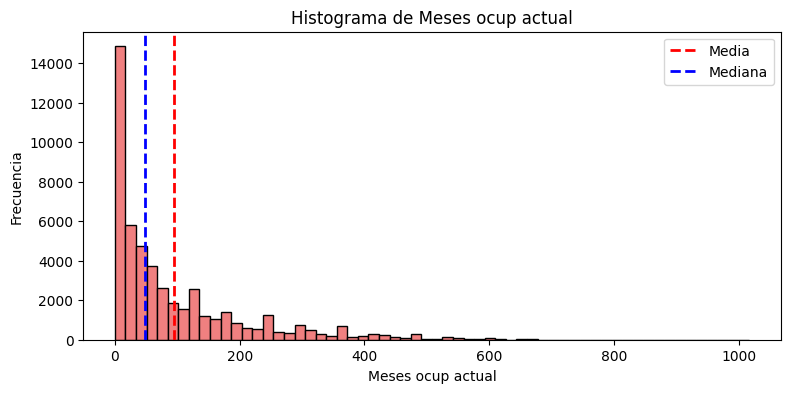

In [ ]:
# histograma de variable meses_ocup_actual con media y mediana como líneas verticales
media_meses_ocup_actual = df['meses_ocup_actual'].mean()
mediana_meses_ocup_actual = df['meses_ocup_actual'].median()
sesgo_meses_ocup_actual = df['meses_ocup_actual'].skew()

print('Media de meses_ocup_actual:', media_meses_ocup_actual)
print('Mediana de meses_ocup_actual:', mediana_meses_ocup_actual)
print('Sesgo:', sesgo_meses_ocup_actual)

plt.hist(df['meses_ocup_actual'], bins=60, color='lightcoral', edgecolor='black')
plt.axvline(media_meses_ocup_actual, color='red', linestyle='dashed', linewidth=2, label='Media')
plt.axvline(mediana_meses_ocup_actual, color='blue', linestyle='dashed', linewidth=2, label='Mediana')
plt.xlabel('Meses ocup actual')
plt.ylabel('Frecuencia')
plt.title('Histograma de Meses ocup actual')
plt.legend()
plt.show()

In [ ]:
print(f'La variable meses_ocup_actual tiene una distribución {tipo_distribucion(media_meses_ocup_actual, mediana_meses_ocup_actual, sesgo_meses_ocup_actual)}')

La variable meses_ocup_actual tiene una distribución Sesgada a la derecha porque el sesgo es mayor a 0.5: 1.8954019418926806


* **Jorobas**: No se observan jorobas.
* **Picks irregulares**: Se observa un acumulamiento de casos cercano al cero, que se explica por las personas sin ocupación o que tienen poco tiempo de estar ocupados; luego decae suavemente la curva.

### ✏️ Actividad 1.2 — Media contra mediana

Para tu variable numérica principal, compara media, mediana y sesgo. Decide cuál de las dos reportarías en un informe y justifícalo.

In [ ]:
print('Media de meses_ocup_actual:', media_meses_ocup_actual)
print('Mediana de meses_ocup_actual:', mediana_meses_ocup_actual)
print('Sesgo:', sesgo_meses_ocup_actual)

print(f'La variable meses_ocup_actual tiene una distribución {tipo_distribucion(media_meses_ocup_actual, mediana_meses_ocup_actual, sesgo_meses_ocup_actual)}')
print(f'''\nJustificación: Reportaría la mediana como medida de tendencia central debido a la distribución sesgada de la variable.
La interpretación sería que la mitad de las observaciones tienen una cantidad de meses con ocupación actual menor o igual a {int(mediana_meses_ocup_actual)} y la otra mitad tiene un valor mayor o igual que eso''')


Media de meses_ocup_actual: 94.99565129857056
Mediana de meses_ocup_actual: 48.0
Sesgo: 1.8954019418926806
La variable meses_ocup_actual tiene una distribución Sesgada a la derecha porque el sesgo es mayor a 0.5: 1.8954019418926806

Justificación: Reportaría la mediana como medida de tendencia central debido a la distribución sesgada de la variable.
La interpretación sería que la mitad de las observaciones tienen una cantidad de meses con ocupación actual menor o igual a 48 y la otra mitad tiene un valor mayor o igual que eso


48 meses son 4 años con ocupación y se diferenciaría mucho de los 94 meses que indica la media (casi el doble). Concluir con la media significaría interpretar que en promedio las observaciones indican casi 8 años de ocupación, cuestión que no refleja una realidad que en la práctica es muy distinta.

### ✏️ Actividad 1.3 — Variables categóricas

Muestra la frecuencia de tus variables categóricas. Fíjate en dos cosas: categorías con muy pocos casos (¿conviene agruparlas?) y categorías que dominan el conjunto (¿sesgan la conclusión?).

In [ ]:
# dataframe con dos columnas: variable del tipo category, object o boolean y la otra columna el listado (set) de valores distintos por variable
resultado = pd.DataFrame({
    'variable': df.select_dtypes(include=['object', 'category', 'boolean']).columns,
    'n_valores_distintos': [
        df[col].nunique(dropna=False)
        for col in df.select_dtypes(include=['object', 'category', 'boolean']).columns
    ],
    'valores_distintos': [
        set(df[col].unique())      # incluye NaN
        for col in df.select_dtypes(include=['object', 'category', 'boolean']).columns
    ]
})

resultado

,variable,n_valores_distintos,valores_distintos
0,mes_central,4,"{8, 2, 11, 5}"
1,mes_encuesta,12,"{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12}"
2,activ,4,"{1, 2, 3, nan}"
3,region,16,"{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
4,tipo,2,"{1, 3}"
5,sexo,2,"{1, 2}"
6,nacionalidad,29,"{642, 276, 152, 410, 32, 804, 170, 56, 826, 19..."
7,orig1,3,"{1, 2, nan}"
8,est_conyugal,8,"{0, 1, 2, 3, 4, 5, 6, nan}"
9,estudia_actual,3,"{1, 2, nan}"


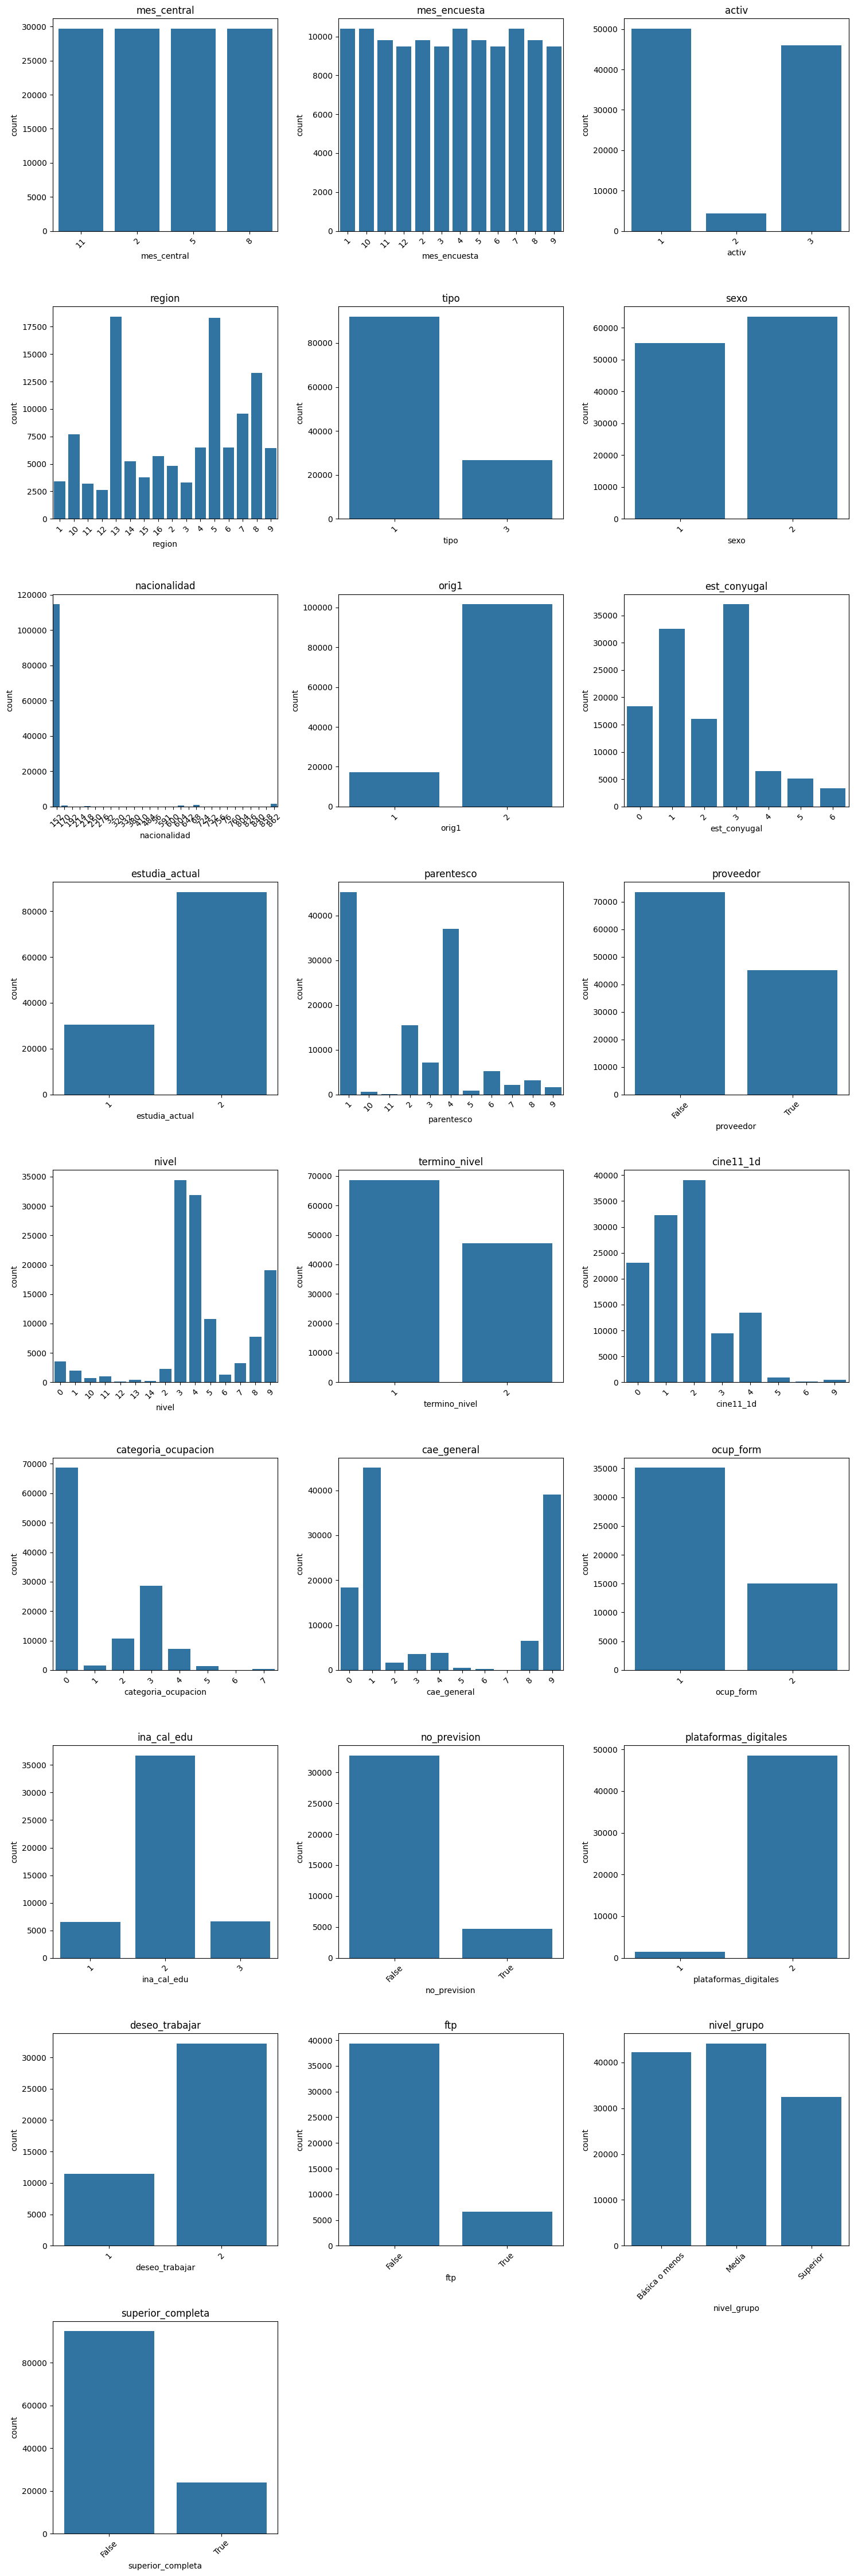

In [ ]:
# matriz de gráficos de barra de las variables tipo category, boolean y object
import matplotlib.pyplot as plt
import seaborn as sns

categorical_cols = df.select_dtypes(include=['category', 'object', 'boolean']).columns
n_cols = 3
n_rows = (len(categorical_cols) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    serie = df[col].dropna().astype(str)  # evita pd.NA, que rompe el ordenamiento de seaborn
    sns.countplot(x=serie, order=sorted(serie.unique()), ax=axes[i])
    axes[i].set_xlabel(col)
    axes[i].set_title(col)
    axes[i].tick_params(axis='x', rotation=45)

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Variables "reduntantes" o candidatas a salir posterior a segunda revisión:

- *mes_encuesta* indica el mes específico en que fue realizada la encuesta, pero en cada caso siempre se respeta que sea una encuestra por trimestre. Y este trimestre se captura en la variable mes_central. **Decisión Bitácora: Remover columna mes_encuesta**
- *parentesco* es una variable que indica el parentesco del entrevistado con el proveedor principal del hogar. La variable proveedor ya captura la condición principal de si la persona es o no el proveedor principal. **Decisión Bitácora: Remover columna parentesco**.
- *nivel_grupo*: Para representar el nivel educacional se conserva la variable nivel_grupo, con tres categorías: básica o menos, media y superior. Se decidió esta agrupación porque el código original nivel tiene 14 valores, varios con pocos casos, y las variables cine11_1d y superior_completa reproducen la misma información con otra clasificación o con un nivel de detalle que el análisis no necesita. cine11_1d depende de nivel y de termino_nivel y solo cambia la clasificación internacional, superior_completa es un subconjunto de la categoría superior, y termino_nivel solo se usa para construir esas variables. Las columnas originales no se eliminan del archivo de respaldo, de modo que el detalle puede recuperarse si una pregunta posterior lo requiere. ina_cal_edu se mantiene aparte porque mide la adecuación entre la educación y la ocupación, un concepto distinto, y solo existe para ocupados. **Decisión Bitácora: Remover columnas: nivel, termino_nivel, cine11_1d, superior_completa.**
- *cae_general*: Se mantiene la variable `cae_general` porque ofrece una clasificación más detallada de la condición laboral que la columna `activ`: separa a los ocupados según su tipo de inserción, a los desocupados según si son cesantes o buscan trabajo por primera vez, y a los inactivos según su búsqueda y disponibilidad. Esa información es útil para describir el empleo y para estudiar transiciones entre grupos. Sin embargo, `cae_general` se construye a partir de la misma condición que `activ`, por lo que cada uno de sus códigos corresponde a un único valor de `activ`. Si se usara como predictora para predecir `activ`, el modelo tendría información perfecta, sin aprender ningún patrón real. Por eso se usa sólo como variable descriptiva, y el modelo predictivo se construye con variables sociodemográficas, educativas y territoriales.**Decisión Bitácora: Mantener columna cae_general para uso descriptivo.**

In [ ]:
patrones = (df.sort_values('mes_encuesta')
            .groupby('idrph')['mes_encuesta']
            .agg(lambda s: tuple(s)))

conteo_patrones = patrones.value_counts().rename('n_personas').to_frame().reset_index()
conteo_patrones

,mes_encuesta,n_personas
0,"(1, 4, 7, 10)",10401
1,"(2, 5, 8, 11)",9812
2,"(3, 6, 9, 12)",9477


In [ ]:
# matriz de casos por mes_encuesta y mes_central mostrando  por mes central
pd.crosstab(df['mes_encuesta'], df['mes_central'], margins=True)

mes_central,2,5,8,11,All
mes_encuesta,,,,,
1,10401,0,0,0,10401
2,9812,0,0,0,9812
3,9477,0,0,0,9477
4,0,10401,0,0,10401
5,0,9812,0,0,9812
6,0,9477,0,0,9477
7,0,0,10401,0,10401
8,0,0,9812,0,9812
9,0,0,9477,0,9477


Las variables categóricas en donde se ven categorías con diferencias notables de frecuencias entre categorías o muchas categorías son:

* *region*: 16 categorías: En donde existen las categorias 5, 8, 13 y 7 destacan . **Decisión Bitácora: Se creará variable que resuma a 8 categorías tomando en consideración cercanía geográfica. Remover columna region**

*  *nacionalidad*: Nacionalidad está técnicamente limpia, pero tiene un desequilibrio fuerte que afecta cualquier modelo. 29 categorías, donde Chile concentra el 96,5 % de los registros (114.632 de 118.760). 19 de las 29 categorías tienen menos de 30 registros. Entre todas suman solo 186 registros, el 0,16 %. Hay 9 con menos de 5. **Decisión Bitácora: Se va a agrupar nacionalidades en categorías 'Chilena' y 'Extranjera' para crear columna 'nacionalidad_grupo'. Remover columna nacionalidad**

* *est_conyugal*: Tiene originalmente 6 categorías que serán recategorizadas según similitud de situación conyugal ('Soltero/a', 'En pareja' y 'Ex pareja'). **Decisión Bitácora: Crear columna 'estado_conyugal_grupo', ejemplo, Casado y Conviviente serán equivalente a 'En pareja'. Remover columna est_conyugal**

* *categoria_ocupacion_grupo* Para describir la posición en el empleo se creará la columna categoria_ocupacion_grupo, a partir de categoria_ocupacion, que tiene ocho códigos. Se agruparon en tres categorías de ocupación y una de no ocupación, según la situación laboral que comparten. Independientes (códigos 1 y 2) y familiares no remunerados (código 7) forman un grupo porque trabajan por cuenta propia o en un negocio, sin depender de un empleador. Asalariados (códigos 3 a 6) incluye al servicio doméstico, porque también es una relación de dependencia y el grupo separado tendría solo 714 personas. La categoría “No ocupado” corresponde al código 0 y se mantiene como categoría propia, porque no es una posición laboral sino la ausencia de empleo. **Decisión Bitácora: se creará la columna categoria_ocupacion_grupo, a partir de categoria_ocupacion. Remover columna categoria_ocupacion**

In [ ]:
# Bitácora: Agrupación de regiones en categorías ordenadas para crear columna 'region_grupo'

MAPA_REGION_GRUPO = {
    13: 'Metropolitana',
    5: 'Valparaíso',
    8: 'Biobío y Ñuble', 16: 'Biobío y Ñuble',
    6: 'Centro', 7: 'Centro',
    1: 'Extremo norte', 15: 'Extremo norte',
    2: 'Norte', 3: 'Norte', 4: 'Norte',
    9: 'Sur', 10: 'Sur', 14: 'Sur',
    11: 'Extremo sur', 12: 'Extremo sur',
}
ORDEN_REGION_GRUPO = ['Extremo norte', 'Norte', 'Valparaíso', 'Metropolitana',
                      'Centro', 'Biobío y Ñuble', 'Sur', 'Extremo sur']

df['region_grupo'] = pd.Categorical(
    pd.to_numeric(df['region'], errors='coerce').map(MAPA_REGION_GRUPO),
    categories=ORDEN_REGION_GRUPO, ordered=True)

# Crosstab de region y region_grupo
pd.crosstab(df['region'], df['region_grupo'], margins=True)

region_grupo,Extremo norte,Norte,Valparaíso,Metropolitana,Centro,Biobío y Ñuble,Sur,Extremo sur,All
region,,,,,,,,,
1,3400,0,0,0,0,0,0,0,3400
2,0,4844,0,0,0,0,0,0,4844
3,0,3292,0,0,0,0,0,0,3292
4,0,6488,0,0,0,0,0,0,6488
5,0,0,18308,0,0,0,0,0,18308
6,0,0,0,0,6480,0,0,0,6480
7,0,0,0,0,9580,0,0,0,9580
8,0,0,0,0,0,13272,0,0,13272
9,0,0,0,0,0,0,6416,0,6416


In [ ]:
from scipy.stats import chi2_contingency

# Test de independencia entre 'tipo' y 'region_grupo' usando chi-cuadrado y V de Cramér para validar si
# existe asociación significativa entre ambas variables

# Para bitácora de tipo y región: Se mantiene variable tipo porque entrega información distinta a region. Evidencia: V de Cramér = 0,247; p < 0,001
ct = pd.crosstab(df['tipo'], df['region_grupo'])
chi2, p, _, _ = chi2_contingency(ct)
n = ct.values.sum()
v_cramer = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print(f'V de Cramér: {v_cramer:.3f}  p-valor: {p:.3g}')

V de Cramér: 0.247  p-valor: 0


In [ ]:
# Bitácora: Agrupación de nacionalidades en categorías 'Chilena' y 'Extranjera' para crear columna 'nacionalidad_grupo'
df['nacionalidad_grupo'] = pd.Categorical(
    np.where(pd.to_numeric(df['nacionalidad'], errors='coerce').eq(152), 'Chilena', 'Extranjera'),
    categories=['Chilena', 'Extranjera'])
df['nacionalidad_grupo'].value_counts(dropna=False)

# Crosstab de nacionalidad y nacionalidad_grupo
pd.crosstab(df['nacionalidad'], df['nacionalidad_grupo'], margins=True)

nacionalidad_grupo,Chilena,Extranjera,All
nacionalidad,,,
32,0,118,118
56,0,4,4
68,0,817,817
76,0,22,22
152,114632,0,114632
170,0,623,623
192,0,32,32
214,0,40,40
218,0,148,148


In [ ]:
# Bitácora: Agrupación de estados conyugales en categorías 'Soltero/a', 'En pareja' y 'Ex pareja' para crear columna 'estado_conyugal_grupo'

MAPA_CONYUGAL = {1: 'En pareja', 2: 'En pareja',
                 3: 'Soltero/a',
                 4: 'Ex pareja', 5: 'Ex pareja', 6: 'Ex pareja'}

df['estado_conyugal_grupo'] = pd.Categorical(
    pd.to_numeric(df['est_conyugal'], errors='coerce').map(MAPA_CONYUGAL),
    categories=['Soltero/a', 'En pareja', 'Ex pareja'])

# Crosstab de estado conyugal y estado_conyugal_grupo
pd.crosstab(df['est_conyugal'], df['estado_conyugal_grupo'], margins=True)

estado_conyugal_grupo,Soltero/a,En pareja,Ex pareja,All
est_conyugal,,,,
1,0,32513,0,32513
2,0,16031,0,16031
3,37017,0,0,37017
4,0,0,6449,6449
5,0,0,5101,5101
6,0,0,3325,3325
All,37017,48544,14875,100436


In [ ]:
MAPA_OCUP = {
    0: 'No ocupado',
    1: 'Independiente', 2: 'Independiente', 7: 'Independiente',
    3: 'Asalariado', 4: 'Asalariado', 5: 'Asalariado', 6: 'Asalariado',
}
ORDEN_OCUP = ['No ocupado', 'Independiente', 'Asalariado']

df['categoria_ocupacion_grupo'] = pd.Categorical(
    pd.to_numeric(df['categoria_ocupacion'], errors='coerce').map(MAPA_OCUP),
    categories=ORDEN_OCUP)

pd.crosstab(df['categoria_ocupacion'], df['categoria_ocupacion_grupo'], margins=True)

categoria_ocupacion_grupo,No ocupado,Independiente,Asalariado,All
categoria_ocupacion,,,,
0,68654,0,0,68654
1,0,1530,0,1530
2,0,10740,0,10740
3,0,0,28682,28682
4,0,0,7277,7277
5,0,0,1383,1383
6,0,0,90,90
7,0,404,0,404
All,68654,12674,37432,118760


In [ ]:
# remover columnas indicadas en apartado de campos redundantes
df.drop(columns=['mes_encuesta', 'parentesco', 'nivel', 'termino_nivel', 'cine11_1d', 'superior_completa'], inplace=True)

# remover columnas originales que fueron agrupadas
df.drop(columns=['nacionalidad', 'est_conyugal', 'region', 'categoria_ocupacion'], inplace=True)

In [ ]:
df.columns

Index(['idrph', 'mes_central', 'fact_anual', 'conglomerado', 'estrato',
       'activ', 'tipo', 'sexo', 'edad', 'orig1', 'estudia_actual', 'proveedor',
       'cae_general', 'ocup_form', 'ina_cal_edu', 'habituales',
       'meses_ocup_actual', 'no_prevision', 'plataformas_digitales',
       'deseo_trabajar', 'ftp', 'nivel_grupo', 'region_grupo',
       'nacionalidad_grupo', 'estado_conyugal_grupo',
       'categoria_ocupacion_grupo'],
      dtype='object')

In [ ]:
df

,idrph,mes_central,fact_anual,conglomerado,estrato,activ,tipo,sexo,edad,orig1,...,meses_ocup_actual,no_prevision,plataformas_digitales,deseo_trabajar,ftp,nivel_grupo,region_grupo,nacionalidad_grupo,estado_conyugal_grupo,categoria_ocupacion_grupo
0,966906226666,2,93.924863,20043,13100312,3,1,2,75,2,...,NaN,<NA>,NaN,2,False,Media,Metropolitana,Chilena,Ex pareja,No ocupado
1,246247268292,2,102.101514,36033,13100313,1,1,1,72,2,...,500.0,False,2,NaN,<NA>,Superior,Metropolitana,Chilena,En pareja,Asalariado
2,254443118268,2,97.354579,36033,13100313,3,1,2,61,1,...,NaN,<NA>,NaN,2,False,Superior,Metropolitana,Chilena,En pareja,No ocupado
3,553075369226,2,15.743992,14530,3200110,3,1,2,76,1,...,NaN,<NA>,NaN,1,False,Básica o menos,Norte,Chilena,Soltero/a,No ocupado
4,724298626488,2,33.690514,13536,8100312,3,1,1,67,2,...,NaN,<NA>,NaN,1,True,Superior,Biobío y Ñuble,Chilena,En pareja,No ocupado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118755,690228697658,11,23.066576,28801,6100120,3,3,1,70,2,...,NaN,<NA>,NaN,2,False,Básica o menos,Centro,Chilena,Soltero/a,No ocupado
118756,788206382825,11,22.324574,28801,6100120,3,3,2,70,2,...,NaN,<NA>,NaN,2,False,Básica o menos,Centro,Chilena,Ex pareja,No ocupado
118757,557584707247,11,37.281391,31712,8100312,3,1,2,48,2,...,NaN,<NA>,NaN,2,False,Media,Biobío y Ñuble,Chilena,En pareja,No ocupado
118758,686395177992,11,25.812065,31106,7100310,3,1,2,68,2,...,NaN,<NA>,NaN,2,False,Básica o menos,Centro,Chilena,Soltero/a,No ocupado


Hasta el momento así es el resumen de variables

| Variable | Rol | Subrol | Tratamiento en el modelo | Observación |
|---|---|---|---|---|
| `sexo` | Predictor | Categórica | Codificación binaria | |
| `orig1` | Predictor | Categórica | Codificación binaria | Dato sensible: control, no factor de discriminación |
| `estudia_actual` | Predictor | Categórica | Codificación binaria | |
| `proveedor` | Predictor | Categórica | Codificación binaria | |
| `tipo` | Predictor | Categórica | Codificación binaria | aporta información distinta a `region_grupo` |
| `region_grupo` | Predictor | Categórica | Codificación binaria | |
| `estado_conyugal_grupo` | Predictor | Categórica | Codificación binaria | |
| `nivel_grupo` | Predictor | Categórica | Codificación binaria | |
| `edad` | Predictor | Numérica | Escalado | |
| `mes_central` | Predictor | Control | Control de trimestre | No es factor de interés |
| `activ` | Objetivo | – | Variable a predecir | |
| `fact_anual` | Diseño y ponderación | Peso | `sample_weight` | Convertir coma decimal antes de usar |
| `conglomerado` | Diseño y ponderación | Diseño | Errores estándar | Fuera de la matriz; identificador sensible |
| `estrato` | Diseño y ponderación | Diseño | Errores estándar | Fuera de la matriz; identificador sensible |
| `idrph` | Llave | – | División por persona | Fuera de la matriz; no publicar |
| `cae_general` | Descriptiva | Define condición | – | Coincide con `activ`; no usar como predictor |
| `ocup_form` | Descriptiva | Solo ocupados | – | |
| `ina_cal_edu` | Descriptiva | Solo ocupados | – | |
| `no_prevision` | Descriptiva | Solo ocupados | – | Solo asalariados |
| `categoria_ocupacion_grupo` | Descriptiva | Solo ocupados | – | |
| `habituales` | Descriptiva | Solo ocupados | – | Declarar valores entre 101 y 168 horas |
| `meses_ocup_actual` | Descriptiva | Solo ocupados | – | Declarar 226 inconsistencias de duración y valor de 1.016 |
| `plataformas_digitales` | Descriptiva | Solo ocupados | – | |
| `deseo_trabajar` | Descriptiva | Solo inactivos | – | |
| `ftp` | Descriptiva | Solo inactivos | – | |
| `nacionalidad_grupo` | Descriptiva | Otras | – | Fuera del modelo por muestra pequeña de extranjeros (3,5 %) |

Resumen: 10 predictores (9 de entrada y `mes_central` como control), 1 objetivo, 3 variables de diseño o llave, 14 descriptivas y 0 eliminadas.

---
## Parte 2 · Análisis bivariado y agrupación

Ahora las relaciones. Aquí es donde empiezan a aparecer los hallazgos, y también los espejismos.

### ✏️ Actividad 2.1 — Comportamiento por grupo

Agrupa por tu variable categórica más importante y compara una métrica numérica entre grupos. Usa `groupby` con al menos tres estadísticos (`count`, `median`, `std`).

**Incluye siempre el `count`.** Una diferencia espectacular entre grupos deja de serlo cuando uno de ellos tiene cuatro casos.

In [ ]:
# group by 'region_grupo' para determinar `count`, media, `mediana`, `std` de edad
df.groupby('region_grupo', observed=True)['edad'].agg(['count', 'mean', 'median', 'std'])

,count,mean,median,std
region_grupo,,,,
Extremo norte,7152,40.221616,39.0,23.262631
Norte,14624,41.143394,41.0,23.048769
Valparaíso,18308,42.748853,43.5,23.360954
Metropolitana,18428,42.309529,43.0,23.313941
Centro,16060,42.600374,44.0,23.261305
Biobío y Ñuble,19000,43.460053,45.0,23.28345
Sur,19364,43.915203,47.0,23.489519
Extremo sur,5824,40.711195,41.0,22.749637


- **Todas las categorías de *region_grupo* tienen al menos 5 mil registros siendo poco más de 19.000 la que más tiene**
- **Respecto a la edad se ven diferencias de la media entre grupos entre 40 y 43 mientras que entre medianas entre 40 y 47.**

### ✏️ Actividad 2.2 — Matriz de correlación

Calcula y grafica la matriz de correlación de tus variables numéricas. Identifica los dos pares con mayor correlación.

In [ ]:
X = df[['edad', 'mes_central', 'nivel_grupo', 'habituales',
        'meses_ocup_actual', 'fact_anual']].apply(
    lambda s: pd.to_numeric(s.astype(str).str.replace(',', '.', regex=False), errors='coerce'))
X = X.mask(X.isin([88, 99, 888, 999, 9999]))   # centinelas por si no se han convertido
matriz = X.corr(method='spearman').round(2)
matriz

,edad,mes_central,nivel_grupo,habituales,meses_ocup_actual,fact_anual
edad,1.00,0.01,NaN,-0.04,0.38,-0.18
mes_central,0.01,1.00,NaN,-0.02,0.01,-0.08
nivel_grupo,NaN,NaN,NaN,NaN,NaN,NaN
habituales,-0.04,-0.02,NaN,1.00,0.13,0.06
meses_ocup_actual,0.38,0.01,NaN,0.13,1.00,-0.05
fact_anual,-0.18,-0.08,NaN,0.06,-0.05,1.00


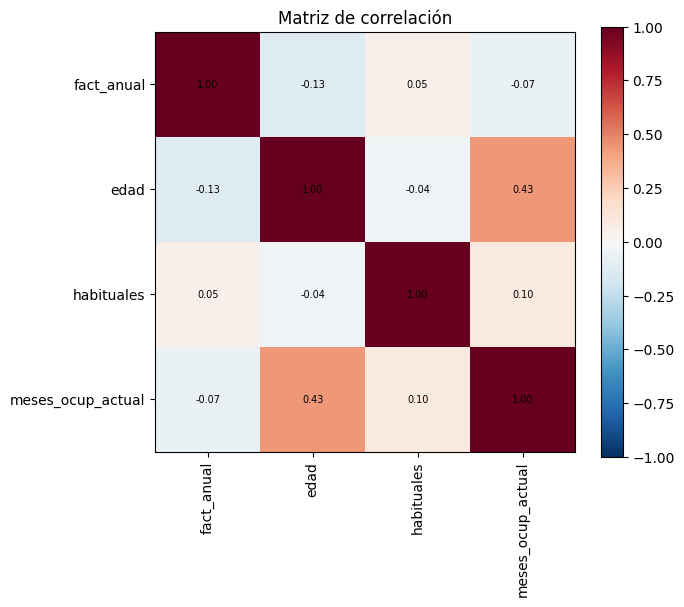

In [ ]:
corr = df.select_dtypes(include='number').corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); plt.title('Matriz de correlación'); plt.tight_layout(); plt.show()

A continuación, se usa Spearman porque las variables que correlacionamos no son todas continuas ni siguen una relación lineal. `mes_central` y `nivel_grupo` son ordinales: tienen orden, pero la distancia entre sus valores no es necesariamente la misma. `edad` y `fact_anual` son numéricas, pero sus distribuciones son asimétricas, y `habituales` y `meses_ocup_actual` tienen valores extremos que aún no he resuelto.

Spearman compara los rangos de los valores y no los valores mismos. Así mide si una variable tiende a aumentar cuando la otra aumenta, sin suponer una forma lineal ni dejarse distorsionar por los extremos. Pearson, en cambio, supondría linealidad y sería sensible a esos valores atípicos, lo que haría que la matriz refleje los extremos más que la tendencia general.

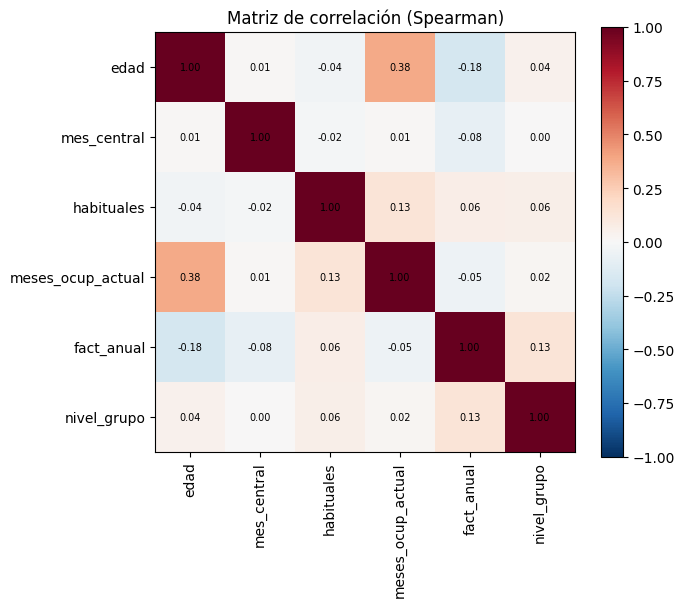

In [ ]:
# 1. Numéricas y ordinales (centinelas ya convertidos a nulo)
cols_num = ['edad', 'mes_central', 'habituales', 'meses_ocup_actual', 'fact_anual']
X = pd.DataFrame({c: pd.to_numeric(df[c], errors='coerce') for c in cols_num})

# 2. nivel_grupo como ordinal: Básica o menos < Media < Superior
orden_nivel = {'Básica o menos': 1, 'Media': 2, 'Superior': 3}
X['nivel_grupo'] = df['nivel_grupo'].map(orden_nivel)

# 3. Spearman
corr = X.corr(method='spearman')

# 4. Mapa de calor
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        valor = corr.iloc[i, j]
        ax.text(j, i, '' if np.isnan(valor) else f'{valor:.2f}',
                ha='center', va='center', fontsize=7)
plt.colorbar(im)
plt.title('Matriz de correlación (Spearman)')
plt.tight_layout()
plt.show()

La matriz no muestra colinealidad relevante entre los predictores numéricos y ordinales. Las correlaciones son débiles, salvo una relación esperable entre `edad` y `meses_ocup_actual` (0,38).

## Conclusión

Entre las variables numéricas y ordinales, la correlación más alta es la de `edad` con `meses_ocup_actual` (0,38). Es una relación previsible: quienes tienen más edad llevan más tiempo en su ocupación actual. Esta relación afecta solo a variables descriptivas, así que no compromete el modelo.

Entre los predictores, las correlaciones son bajas. `edad` tiene 0,04 con `nivel_grupo` y 0,01 con `mes_central`. `nivel_grupo` tiene 0,13 con `fact_anual` y 0,06 con `habituales`. `mes_central` prácticamente no se relaciona con las demás variables (valores entre −0,08 y 0,01). Ninguna correlación entre predictores supera 0,13 en valor absoluto, así que no hay señal de que una variable sustituya a otra en el modelo.

Las correlaciones de `fact_anual` con `edad` (−0,18) y con `mes_central` (−0,08) reflejan el diseño de la muestra y los factores de expansión, no una relación sustantiva entre las personas. Por eso no deben interpretarse como efectos.

## Advertencias

- **`habituales` y `meses_ocup_actual`** solo tienen datos para ocupados, así que sus correlaciones se calculan sobre ese subgrupo. No son comparables con las del resto de la población.
- **`nivel_grupo` como ordinal** pierde el detalle de los 14 niveles. Una correlación más fina requeriría usar `nivel` original.
- **Correlación no es efecto.** La matriz describe relaciones lineales o de orden entre variables, pero no dice cuál es la causa. Eso lo validaremos en el modelo.

Bitácora: No se detecta colinealidad entre predictores numéricos y ordinales (todas las correlaciones entre predictores son menores a 0,15 en valor absoluto), y la única relación fuerte observada, entre edad y antigüedad en la ocupación, corresponde a variables descriptivas.

### ✏️ Actividad 2.3 — El par más correlacionado, bajo sospecha

Toma el par con mayor correlación y **no te quedes con el número**. Haz el recorrido del Ejercicio 4:

1. Grafica el diagrama de dispersión. ¿La relación es lineal, o el coeficiente engaña?
2. ¿Alguna de las dos variables depende del **tamaño** de la unidad de análisis? Si es así, **normalízalas** y vuelve a calcular.
3. Piensa qué **tercera variable** podría estar causando ambas, y calcula la correlación parcial.
4. Si tienes una variable de agrupación, repite el cálculo **dentro de un solo grupo**.

r(edad, meses_ocup_actual) = 0.380


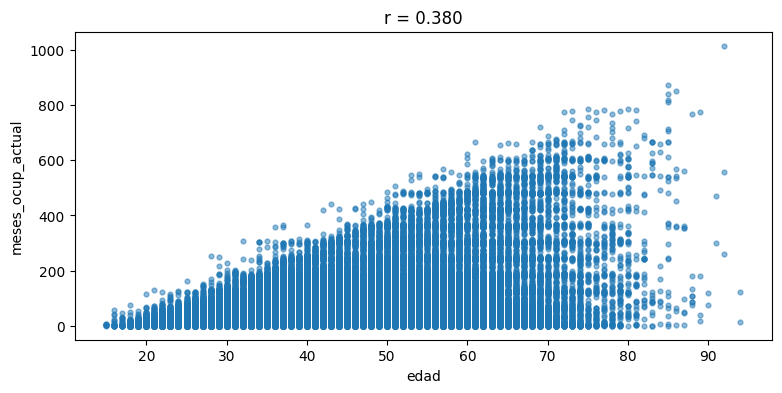

In [ ]:
h = df['edad']
b = df['meses_ocup_actual']
t = df['edad'] # lo haré con la edad por lo importante es capturar el paso del tiempo

print(f'r(edad, meses_ocup_actual) = {h.corr(b, method='spearman'):.3f}')

plt.scatter(h, b, s=12, alpha=0.5)
plt.xlabel('edad'); plt.ylabel('meses_ocup_actual')
plt.title(f'r = {h.corr(b, method='spearman'):.3f}'); plt.show()

In [ ]:
# def correlacion_parcial(x, y, z):
#     """Correlación entre x e y una vez removido el efecto lineal de z."""
#     res_x = x - np.polyval(np.polyfit(z, x, 1), z)
#     res_y = y - np.polyval(np.polyfit(z, y, 1), z)
#     return np.corrcoef(res_x, res_y)[0, 1]

from scipy.stats import rankdata

def correlacion_parcial_spearman(x, y, z):
    """Correlación de Spearman entre x e y, removido el efecto de z.
    Trabaja con rangos, así que no asume linealidad ni se distorsiona por extremos."""
    x, y, z = (np.asarray(v, dtype=float) for v in (x, y, z))
    ok = ~(np.isnan(x) | np.isnan(y) | np.isnan(z))   # solo casos completos
    rx = rankdata(x[ok])
    ry = rankdata(y[ok])
    rz = rankdata(z[ok])
    res_x = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    res_y = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return np.corrcoef(res_x, res_y)[0, 1]

# Tu código aquí

print(f'r crudo                       = {h.corr(b, method='spearman'):.3f}')
print(f'r parcial | edad       = {correlacion_parcial_spearman(h, b, t):.3f}')
print(f'r(edad, edad)        = {h.corr(t, method='spearman'):.3f}')

r crudo                       = 0.380
r parcial | edad       = 0.001
r(edad, edad)        = 1.000


### Paso 3 · Quitar el efecto del paso del tiempo, es decir dividir por la edad

In [ ]:
df['edad_edad'] = df['edad'] / df['edad']
df['meses_ocup_actual_edad']   = df['meses_ocup_actual'] / df['edad']

hm, bm = df['edad_edad'], df['meses_ocup_actual_edad']

print(f'r(edad/edad, meses_ocup_actual/edad)       = {hm.corr(bm, method="spearman"):.3f}')
print(f'r(edad/edad, edad)         = {hm.corr(t, method="spearman"):.3f}   <- ahora sí')
print(f'r parcial | edad           = {correlacion_parcial_spearman(hm, bm, t):.3f}   <- colapsa')

r(edad/edad, meses_ocup_actual/edad)       = nan
r(edad/edad, edad)         = nan   <- ahora sí
r parcial | edad           = 0.001   <- colapsa


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]
/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


/usr/local/lib/python3.13/dist-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


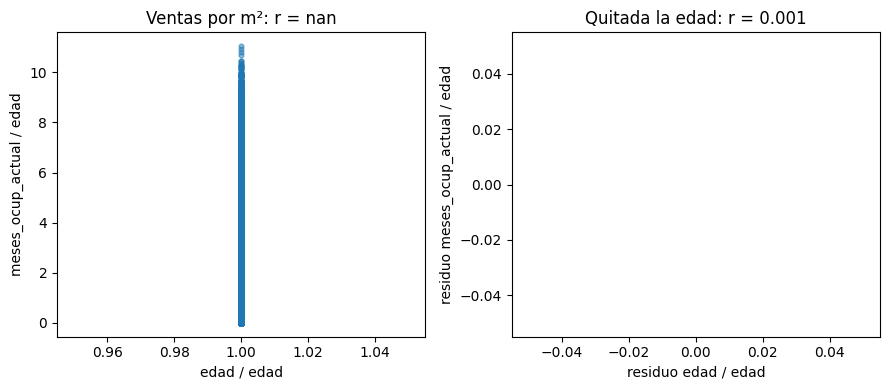

In [ ]:
fig, ax = plt.subplots(1, 2)
ax[0].scatter(hm, bm, s=12, alpha=0.5)
ax[0].set_title(f'Ventas por m²: r = {hm.corr(bm, method="spearman"):.3f}')
ax[0].set_xlabel('edad / edad'); ax[0].set_ylabel('meses_ocup_actual / edad')

res_h = hm - np.polyval(np.polyfit(t, hm, 1), t)
res_b = bm - np.polyval(np.polyfit(t, bm, 1), t)
ax[1].scatter(res_h, res_b, s=12, alpha=0.5, color='C1')
ax[1].set_title(f'Quitada la edad: r = {correlacion_parcial_spearman(hm, bm, t):.3f}')
ax[1].set_xlabel('residuo edad / edad'); ax[1].set_ylabel('residuo meses_ocup_actual / edad')
plt.tight_layout(); plt.show()

**Lo que cambia en este caso en relación al ejercicio 4 resuelto**

- En el ejercicio 4, ventas / m² es una normalización válida porque la superficie es la escala que genera las ventas.
- En este caso, el problema con meses / edad no era dividir por una variable, sino elegir mal el denominador. La escala natural de meses_ocup_actual es el tiempo posible desde los 15 años, (edad − 15) × 12. Dividir entre edad incluye años en los que nadie pudo trabajar.

Por eso la proporción meses / ((edad − 15) × 12) sí es el equivalente correcto de ventas / m².

In [ ]:
# Variables
e = pd.to_numeric(df['edad'], errors='coerce')
m = pd.to_numeric(df['meses_ocup_actual'].astype(str).str.replace(',', '.', regex=False),
                  errors='coerce')
nivel = df['nivel_grupo'].map({'Básica o menos': 1, 'Media': 2, 'Superior': 3})

In [ ]:
from scipy.stats import rankdata

def correlacion_parcial_spearman(x, y, z):
    """Spearman entre x e y, removido el efecto de z. Usa solo casos completos."""
    x, y, z = (np.asarray(v, dtype=float) for v in (x, y, z))
    ok = ~(np.isnan(x) | np.isnan(y) | np.isnan(z))
    rx, ry, rz = rankdata(x[ok]), rankdata(y[ok]), rankdata(z[ok])
    res_x = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    res_y = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    return np.corrcoef(res_x, res_y)[0, 1]

Bloque A: el mecanismo del techo

meses_ocup_actual no puede superar los meses posibles desde los 15 años. Ese techo crece con la edad, así que parte de la correlación con la edad es mecánica. Comparamos la correlación bruta con la normalizada.

r(edad, meses) bruta        = 0.380
r(edad, proporción)         = 0.078
Casos que superan el techo  = 219 (excluidos de la proporción)


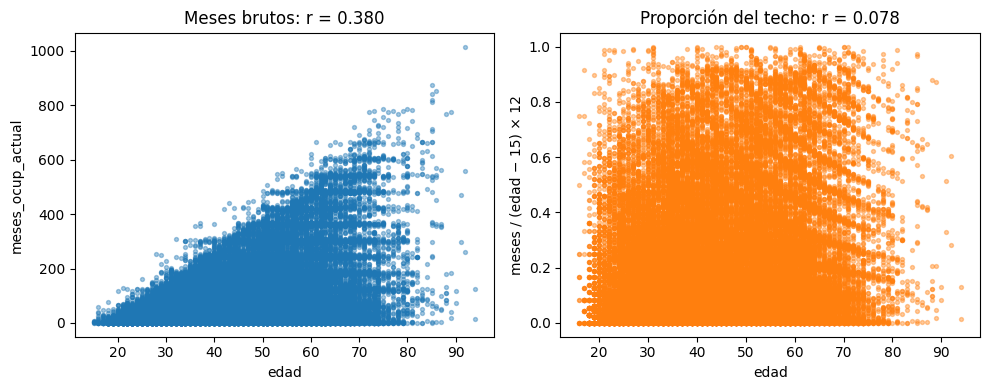

In [ ]:
pot = (e - 15) * 12                                   # meses posibles desde los 15 años
prop = (m / pot).where((pot > 0) & (m <= pot))        # proporción, solo casos plausibles

r_bruta = e.corr(m, method='spearman')
r_norm  = e.corr(prop, method='spearman')
violaciones = int(((m > pot) & (pot > 0)).sum())

print(f'r(edad, meses) bruta        = {r_bruta:.3f}')
print(f'r(edad, proporción)         = {r_norm:.3f}')
print(f'Casos que superan el techo  = {violaciones} (excluidos de la proporción)')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(e, m, s=8, alpha=0.4)
ax[0].set_title(f'Meses brutos: r = {r_bruta:.3f}')
ax[0].set_xlabel('edad'); ax[0].set_ylabel('meses_ocup_actual')
ax[1].scatter(e, prop, s=8, alpha=0.4, color='C1')
ax[1].set_title(f'Proporción del techo: r = {r_norm:.3f}')
ax[1].set_xlabel('edad'); ax[1].set_ylabel('meses / (edad − 15) × 12')
plt.tight_layout(); plt.show()

**_Lectura. La caída de 0,38 a 0,08 muestra que la mayor parte de la relación edad-meses es el techo. La edad sigue siendo la causa del techo, pero no implica que las personas acumulen más experiencia a mayor edad de forma sustantiva._**

---
## Parte 3 · Series temporales

**Si tu conjunto tiene una variable de fecha, esta parte es obligatoria.** Si no la tiene, reemplázala por un análisis bivariado adicional y dilo explícitamente aquí.

- **Existe un campo de tiempo llamado mes_central que ahce referencia el trimestre de observación durante el año 2025. Dado que son sólo cuatro casos por persona (uno por trimestre) no permite un análisis de serie temporal propiamente, sino que se usará para otros análisis descriptivos eventualmente**
- **Se realizará un par de análisis bivariado adicionales**

### ✏️ Actividad 3.1 — Construir la serie

Agrega tu conjunto por período (mes, semana o día, según corresponda) y grafica la evolución de tu métrica principal.

In [ ]:
# Será análisis bivariado

def num(col):
    return pd.to_numeric(df[col].astype(str).str.replace(',', '.', regex=False), errors='coerce')

w = num('fact_anual')
activ = num('activ')
ft = activ.isin([1, 2])                 # fuerza de trabajo
desoc = activ.eq(2)

# tabla = []
# for grupo in ['Básica o menos', 'Media', 'Superior']:
#     mask = ft & df['nivel_grupo'].eq(grupo)
#     tasa = (w[mask & desoc].sum() / w[mask].sum()) * 100
#     n = int(mask.sum())
#     tabla.append({'nivel_grupo': grupo, 'fuerza_trabajo': n, 'tasa_desocupacion_%': round(tasa, 2)})

# print(pd.DataFrame(tabla).to_string(index=False))

In [ ]:
def tasa_por(df, var, etiquetas=None):
    """Tasa de desocupación ponderada por grupo de `var`, solo fuerza de trabajo."""
    num = lambda c: pd.to_numeric(df[c].astype(str).str.replace(',', '.', regex=False),
                                  errors='coerce')
    w, a = num('fact_anual'), num('activ')
    grupo = df[var] if etiquetas is None else num(var).map(etiquetas)
    tmp = pd.DataFrame({'g': grupo, 'w': w, 'des': a.eq(2), 'ft': a.isin([1, 2])})
    tmp = tmp[tmp['ft']]
    return tmp.groupby('g', observed=True).apply(
        lambda x: pd.Series({'fuerza_trabajo': len(x),
                             'tasa_desocupacion_%': round(x.loc[x.des, 'w'].sum() / x['w'].sum() * 100, 2)}))

In [ ]:
tasa_por(df, 'region_grupo')

/tmp/ipykernel_42035/61345830.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return tmp.groupby('g', observed=True).apply(


,fuerza_trabajo,tasa_desocupacion_%
g,,
Extremo norte,3261.0,10.38
Norte,6898.0,8.66
Valparaíso,8681.0,8.31
Metropolitana,8748.0,9.85
Centro,7124.0,7.19
Biobío y Ñuble,8242.0,8.72
Sur,8357.0,7.22
Extremo sur,3178.0,4.29


In [ ]:
tasa_por(df, 'sexo', {1: 'Hombre', 2: 'Mujer'})

/tmp/ipykernel_42035/61345830.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return tmp.groupby('g', observed=True).apply(


,fuerza_trabajo,tasa_desocupacion_%
g,,
Hombre,29488.0,8.14
Mujer,25001.0,9.49


In [ ]:
tasa_por(df, 'estado_conyugal_grupo')

/tmp/ipykernel_42035/61345830.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return tmp.groupby('g', observed=True).apply(


,fuerza_trabajo,tasa_desocupacion_%
g,,
Soltero/a,19263.0,13.21
En pareja,28680.0,6.05
Ex pareja,6545.0,6.97


In [ ]:
tasa_por(df, 'nivel_grupo')

/tmp/ipykernel_42035/61345830.py:9: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return tmp.groupby('g', observed=True).apply(


,fuerza_trabajo,tasa_desocupacion_%
g,,
Básica o menos,8879.0,6.47
Media,23357.0,9.57
Superior,22251.0,8.58


Estas son las conclusiones de las cuatro tablas. Todas son tasas de desocupación ponderadas por `fact_anual`, calculadas sobre la fuerza de trabajo.

**Región.** La brecha territorial es la más grande de los casos: el Extremo norte tiene 10,4 % y el Extremo sur 4,3 %, una diferencia de seis puntos. Metropolitana (9,9 %) y Extremo norte son las regiones con más desocupación, mientras que Centro, Sur y Extremo sur están por debajo del promedio. Como la clasificación es de agrupaciones geográficas propias, conviene verificar que las regiones de cada grupo estén bien asignadas antes de publicar.

**Sexo.** Las mujeres tienen 9,5 % de desocupación frente a 8,1 % de los hombres. Es una brecha de 1,4 puntos, pequeña pero consistente con lo esperado. Si el informe enfatiza género, conviene presentar un intervalo de confianza, porque la brecha es modesta frente al error muestral.

**Estado conyugal.** Es la diferencia más marcada entre grupos de personas: solteros/as con 13,2 % frente a 6,1 % en pareja y 7,0 % en ex pareja. Como estado conyugal y edad están asociados, parte de esta brecha puede deberse a que los solteros son más jóvenes. Por eso conviene verificarla en el análisis multivariado con edad.

**Nivel educativo.** La tasa sube de básica o menos (6,5 %) a media (9,6 %), y baja en superior (8,6 %). Es una relación no lineal. La explicación más probable es la composición: en básica o menos hay más personas fuera de la fuerza de trabajo, y quienes participan en ella suelen ser un grupo seleccionado. Por eso la tabla describe la fuerza de trabajo, no el total de personas de cada nivel.

**Lectura de conjunto.** Las brechas más grandes aparecen entre territorios y estados conyugales, no entre sexos. Para el informe, esa comparación de magnitudes es más útil que la lista de tasas, y debe acompañarse de la advertencia de que son asociaciones descriptivas.

### ✏️ Actividad 3.2 — Descomposición

Si tu serie tiene al menos **dos ciclos completos** (por ejemplo, 24 meses), descompónla en tendencia, estacionalidad y residuo.

Después responde: ¿qué muestra el **residuo**? ¿Hay algún período anómalo?

In [ ]:
# from statsmodels.tsa.seasonal import seasonal_decompose
# desc = seasonal_decompose(serie, model='additive', period=12)
# fig = desc.plot(); fig.set_size_inches(9, 8); plt.tight_layout(); plt.show()

# Tu código aquí


_Tu lectura de la tendencia, la estacionalidad y el residuo:_



### ✏️ Actividad 3.3 — La comparación honesta

Si tu serie tiene estacionalidad, calcula la variación entre dos períodos consecutivos y la variación interanual del mismo período. Muestra la diferencia entre ambas lecturas (Ejercicio 6).

In [ ]:
# Tu código aquí


---
## Parte 4 · Hipótesis de trabajo

Esto es lo que la semana 4 va a poner a prueba. Una hipótesis de trabajo no es una corazonada: es una afirmación **falsable** que surge de la evidencia que acabas de producir.

### ✏️ Actividad 4.1 — Formula dos hipótesis

Cada una debe indicar:

- **La afirmación**, en una frase.
- **La evidencia exploratoria** que la sugiere (qué gráfico, qué número, en qué celda).
- **Qué la refutaría**: qué tendrías que observar para descartarla.
- **Qué confundidor podría explicarla** sin que la relación sea real.

Si no puedes escribir qué la refutaría, no es una hipótesis: es una opinión.

**Hipótesis 1**

- Afirmación: _…_
- Evidencia: _…_
- Qué la refutaría: _…_
- Confundidor posible: _…_

**Hipótesis 2**

- Afirmación: _…_
- Evidencia: _…_
- Qué la refutaría: _…_
- Confundidor posible: _…_

Dos hipótesis, cada una con su evidencia y lo que la refutaría:

## Hipótesis 1 · Nivel educativo y desocupación

- **Afirmación:** la desocupación es mayor entre quienes tienen educación media que entre quienes tienen básica o menos, y esta diferencia se mantiene al controlar por edad.
- **Evidencia exploratoria:** `tasa_por(df, 'nivel_grupo')` da 6,47 % en básica o menos, 9,57 % en media y 8,58 % en superior. La correlación parcial de Spearman entre nivel y proporción de vida laboral ocupada, controlando por edad, es 0,167.
- **Qué la refutaría:** que, dentro de cada tramo de edad, la tasa de media no sea mayor que la de básica o menos. También que la diferencia desaparezca al estratificar por edad.
- **Confundidor posible:** la edad. Quienes tienen básica o menos suelen ser mayores y salir de la fuerza de trabajo con más frecuencia, así que la tabla puede reflejar quién participa y no el efecto del nivel.

## Hipótesis 2 · Brecha por sexo

- **Afirmación:** la desocupación es mayor entre mujeres que entre hombres, y la brecha se concentra en el nivel educativo medio.
- **Evidencia exploratoria:** `tasa_por(df, 'sexo', {1: 'Hombre', 2: 'Mujer'})` da 9,49 % en mujeres y 8,14 % en hombres. La brecha dentro de cada nivel es 0,50 en básica o menos, 3,08 en media y 0,03 en superior.
- **Qué la refutaría:** que la brecha dentro del nivel medio se reduzca a cero al controlar por edad o estado conyugal. Eso indicaría que la diferencia viene de otra variable y no del sexo.
- **Confundidor posible:** la edad y el estado conyugal, que también difieren entre sexos y se asocian con la desocupación.

---
## Parte 5 · Cierre y versionado

In [ ]:
df

,idrph,mes_central,fact_anual,conglomerado,estrato,activ,tipo,sexo,edad,orig1,...,plataformas_digitales,deseo_trabajar,ftp,nivel_grupo,region_grupo,nacionalidad_grupo,estado_conyugal_grupo,categoria_ocupacion_grupo,edad_edad,meses_ocup_actual_edad
0,966906226666,2,93.924863,20043,13100312,3,1,2,75,2,...,NaN,2,False,Media,Metropolitana,Chilena,Ex pareja,No ocupado,1.0,<NA>
1,246247268292,2,102.101514,36033,13100313,1,1,1,72,2,...,2,NaN,<NA>,Superior,Metropolitana,Chilena,En pareja,Asalariado,1.0,6.944444
2,254443118268,2,97.354579,36033,13100313,3,1,2,61,1,...,NaN,2,False,Superior,Metropolitana,Chilena,En pareja,No ocupado,1.0,<NA>
3,553075369226,2,15.743992,14530,3200110,3,1,2,76,1,...,NaN,1,False,Básica o menos,Norte,Chilena,Soltero/a,No ocupado,1.0,<NA>
4,724298626488,2,33.690514,13536,8100312,3,1,1,67,2,...,NaN,1,True,Superior,Biobío y Ñuble,Chilena,En pareja,No ocupado,1.0,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
118755,690228697658,11,23.066576,28801,6100120,3,3,1,70,2,...,NaN,2,False,Básica o menos,Centro,Chilena,Soltero/a,No ocupado,1.0,<NA>
118756,788206382825,11,22.324574,28801,6100120,3,3,2,70,2,...,NaN,2,False,Básica o menos,Centro,Chilena,Ex pareja,No ocupado,1.0,<NA>
118757,557584707247,11,37.281391,31712,8100312,3,1,2,48,2,...,NaN,2,False,Media,Biobío y Ñuble,Chilena,En pareja,No ocupado,1.0,<NA>
118758,686395177992,11,25.812065,31106,7100310,3,1,2,68,2,...,NaN,2,False,Básica o menos,Centro,Chilena,Soltero/a,No ocupado,1.0,<NA>


In [ ]:
# Guarda el conjunto limpio. Este archivo es el insumo de la semana 4.

import os

RUTA_semana3 = '/content/drive/Othercomputers/Notebook HP/Ing Informática UCSC/Trimestre 3/1 Ciencia de datos/Evaluaciones/Semana 3/'

if not os.path.exists(RUTA_semana3 + 'mi_conjunto_explorado.csv'):
    df.to_csv(RUTA_semana3 +'mi_conjunto_explorado.csv', sep=';', index=False, encoding='utf-8')
    print('Archivo guardado: mi_conjunto_explorado.csv en', RUTA_semana3, df.shape)
else:
    print('Archivo no guardado: mi_conjunto_explorado.csv ya existe en', RUTA_semana3, df.shape)

Archivo guardado: mi_conjunto_explorado.csv en /content/drive/Othercomputers/Notebook HP/Ing Informática UCSC/Trimestre 3/1 Ciencia de datos/Evaluaciones/Semana 3/ (118760, 28)


In [ ]:
# # Guarda el conjunto con las variables derivadas que hayas creado esta semana
# df.to_csv(RUTA + 'mi_conjunto_explorado.csv', sep=';', index=False)
# print('Guardado:', df.shape)

In [ ]:
# En una terminal:
# git add S3_Notebook_Laboratorio_CDD.ipynb mi_conjunto_explorado.csv
# git commit -m 'Semana 3: analisis exploratorio y series temporales'
# git push


**Enlace a mi repositorio:** [https://github.com/hersil7/cdd_ucsc](https://github.com/hersil7/cdd_ucsc)

---

## Antes de entregar

- [ ] Al menos tres distribuciones graficadas y **leídas**, no solo mostradas
- [ ] Media contra mediana decidida y justificada
- [ ] Comparación por grupos con el `count` incluido
- [ ] Matriz de correlación calculada e interpretada
- [ ] El par más correlacionado sometido al recorrido de confundidores
- [ ] Serie temporal descompuesta, con lectura del residuo (o justificación de por qué no aplica)
- [ ] Dos hipótesis de trabajo, cada una con qué la refutaría
- [ ] Cada celda de código seguida de su celda de interpretación
- [ ] Cuaderno ejecutado de principio a fin, con las salidas visibles

Recuerda: **esta semana no hay sesión sincrónica**. Las dudas, al Foro de Consultas.

_Ciencia de Datos · Advance UCSC · Semana 3_